In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv("iris (3).csv")
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [19]:
x=df[['petal_length','petal_width','sepal_length','sepal_width']]
y=df[['species']]


In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_data = pd.DataFrame(scaler.fit_transform(x))


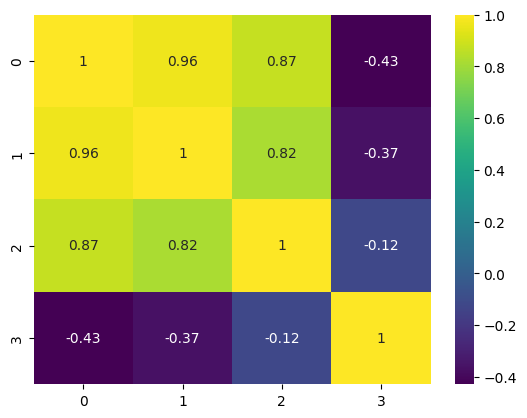

In [27]:
sns.heatmap(scaled_data.corr(), cmap='viridis', annot=True)
plt.show()

In [28]:
from sklearn.decomposition import PCA
pca = PCA(n_components=4)
pca.fit(scaled_data)
X_pca = pca.transform(scaled_data)
X_pca = pd.DataFrame( X_pca,columns=['PC1', 'PC2', 'PC3', 'PC4'])
print(X_pca.head())

        PC1       PC2       PC3       PC4
0 -2.264703  0.480027  0.127706 -0.024168
1 -2.080961 -0.674134  0.234609 -0.103007
2 -2.364229 -0.341908 -0.044201 -0.028377
3 -2.299384 -0.597395 -0.091290  0.065956
4 -2.389842  0.646835 -0.015738  0.035923


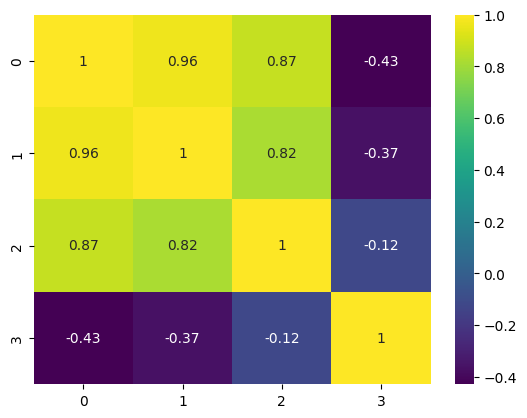

In [29]:
sns.heatmap(scaled_data.corr(), cmap='viridis', annot=True)
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X_pca, y,  test_size=0.2,  random_state=3)

In [36]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [37]:
y_pred = dtc.predict(X_test)

In [38]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test, y_pred)
print("Accuracy =", acc)

Accuracy = 1.0
